In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Visualization environment is ready!")

Visualization environment is ready!


In [2]:
data_folder = r"P:\OneDrive\Documents\TMDB_Movie_Analytics\data"

movies = pd.read_csv(os.path.join(data_folder, "movies_cleaned.csv"))
genres = pd.read_csv(os.path.join(data_folder, "genres_cleaned.csv"))
movie_genres = pd.read_csv(os.path.join(data_folder, "movie_genres_cleaned.csv"))
cast = pd.read_csv(os.path.join(data_folder, "cast_cleaned.csv"))
crew = pd.read_csv(os.path.join(data_folder, "crew_cleaned.csv"))
movie_keywords = pd.read_csv(os.path.join(data_folder, "movie_keywords_cleaned.csv"))

# Convert release date into datetime format
movies["release_date"] = pd.to_datetime(movies["release_date"])

print("All six cleaned datasets loaded successfully!")
print("Movies:", len(movies))
print("Genres:", len(genres))

All six cleaned datasets loaded successfully!
Movies: 2503
Genres: 19


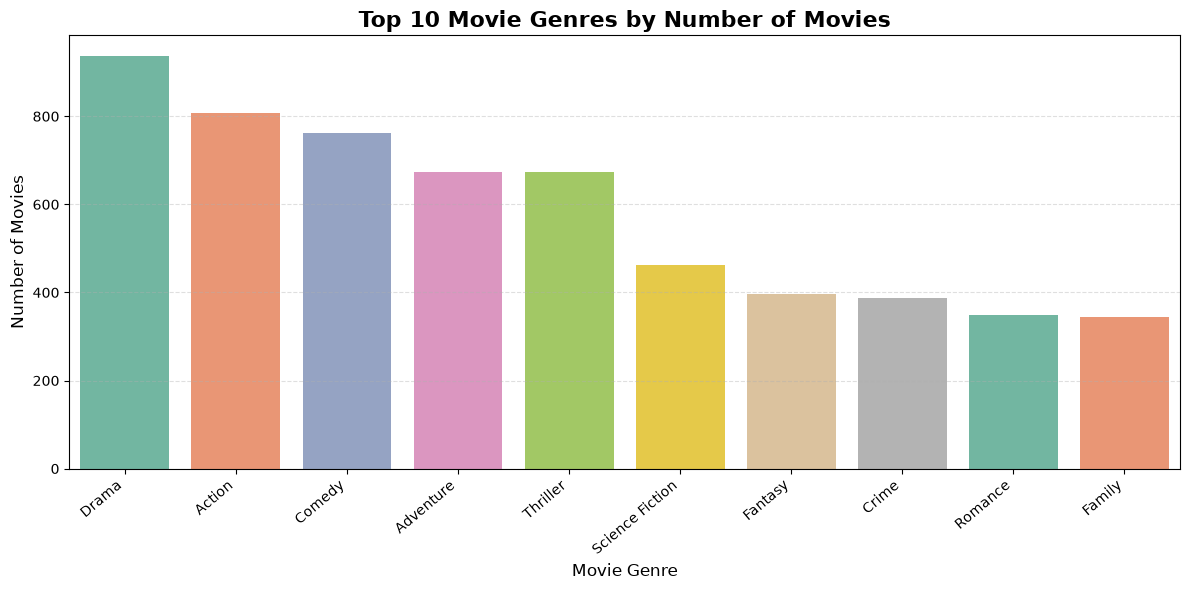

In [13]:
# Count movies belonging to each genre
genre_counts = (
    movie_genres
    .merge(genres, on="genre_id")
    .groupby("genre_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

# Create colourful vertical bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.index,
    y=genre_counts.values,
    hue=genre_counts.index,
    palette="Set2",
    legend=False
)

plt.title("Top 10 Movie Genres by Number of Movies",
          fontsize=16, fontweight="bold")
plt.xlabel("Movie Genre", fontsize=12)
plt.ylabel("Number of Movies", fontsize=12)
plt.xticks(rotation=40, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Insight:

Drama is the most represented genre in the dataset, followed by Action and Comedy. Adventure and Thriller also have a strong presence. Romance and Family have comparatively fewer movies among the top 10 genres. This indicates that the dataset contains a wide variety of movies, with Drama being particularly prominent.


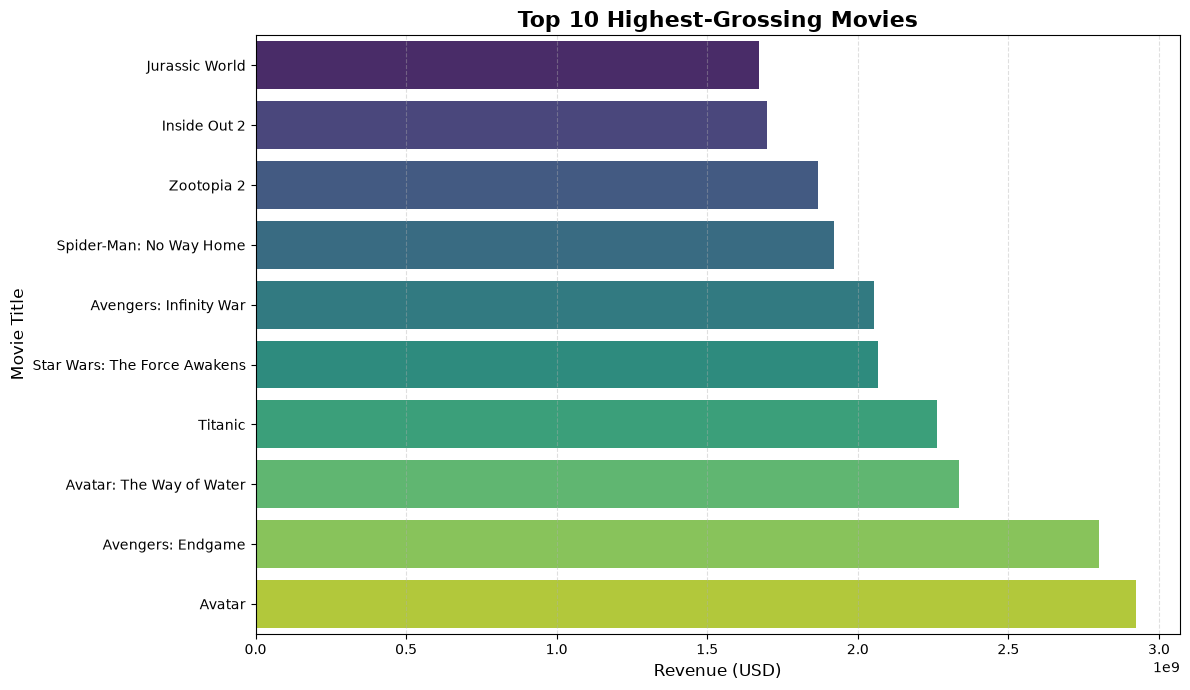

In [14]:
# Select the top 10 highest-grossing movies
top_revenue = (
    movies[movies["revenue"] > 0]
    .nlargest(10, "revenue")
    .sort_values("revenue", ascending=True)
)

# Create colourful horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_revenue,
    x="revenue",
    y="title",
    hue="title",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Highest-Grossing Movies",
          fontsize=16, fontweight="bold")
plt.xlabel("Revenue (USD)", fontsize=12)
plt.ylabel("Movie Title", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Insight:**

The chart compares the revenue generated by the ten highest-grossing movies in the dataset. It highlights the differences in commercial performance among these movies. The results show that some movies achieve considerably higher box-office revenue than others, demonstrating the variation in financial success within the movie industry. 


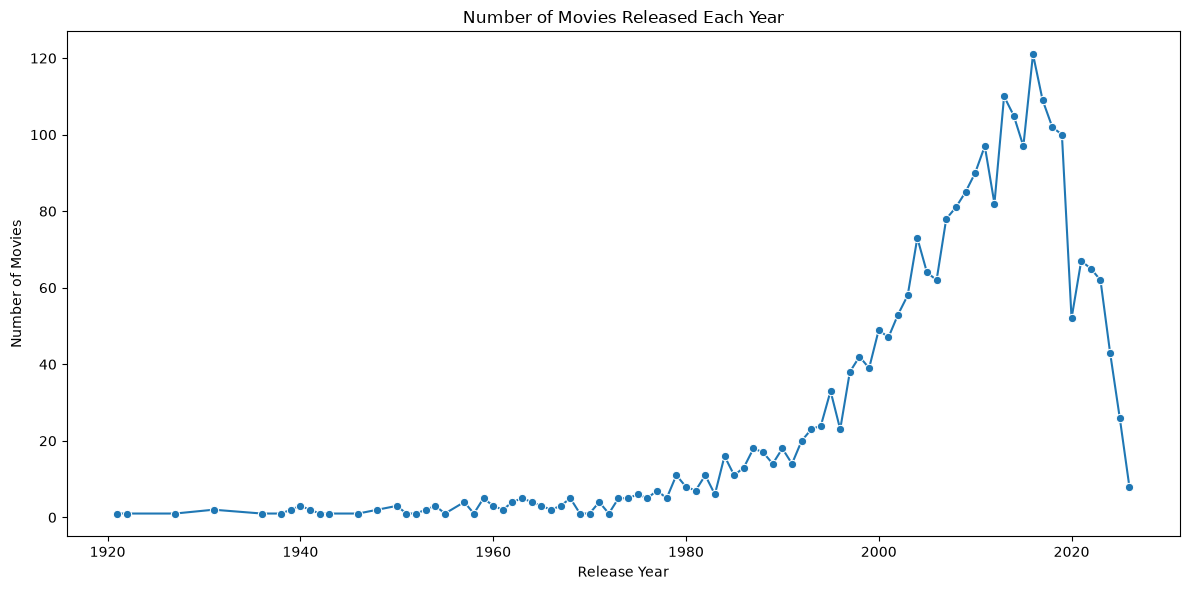

In [5]:
# Extract release year
movies["release_year"] = movies["release_date"].dt.year

# Count movies released each year
yearly_movies = (
    movies.groupby("release_year")["movie_id"]
    .nunique()
    .reset_index(name="movie_count")
)

# Create line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_movies,
    x="release_year",
    y="movie_count",
    marker="o"
)

plt.title("Number of Movies Released Each Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

**Insight:**

The line chart illustrates how the number of movie releases changes over the years. The peaks indicate years with a higher number of movie releases, while the dips represent years with fewer releases. This helps identify changes in movie production activity over time.


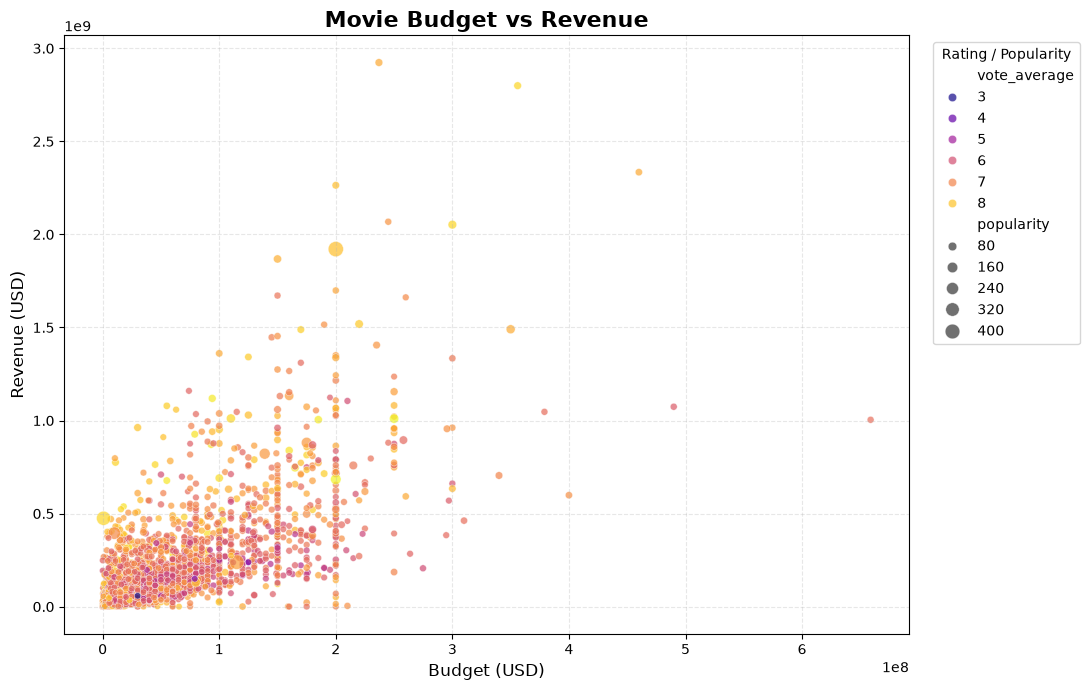

In [15]:
# Select movies with valid budget and revenue
financial_data = movies[
    (movies["budget"] > 0) &
    (movies["revenue"] > 0)
]

# Create an improved scatter plot
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=financial_data,
    x="budget",
    y="revenue",
    hue="vote_average",
    palette="plasma",
    size="popularity",
    sizes=(20, 120),
    alpha=0.7
)

plt.title("Movie Budget vs Revenue",
          fontsize=16, fontweight="bold")
plt.xlabel("Budget (USD)", fontsize=12)
plt.ylabel("Revenue (USD)", fontsize=12)

plt.grid(linestyle="--", alpha=0.3)
plt.legend(title="Rating / Popularity",
           bbox_to_anchor=(1.02, 1),
           loc="upper left")

plt.tight_layout()
plt.show()

**Insight:**

The scatter plot explores the relationship between movie budgets and their revenue. It helps identify whether movies with higher production budgets tend to generate higher earnings. The different colours represent movie ratings, while bubble sizes indicate popularity, allowing financial performance and audience response to be examined together.


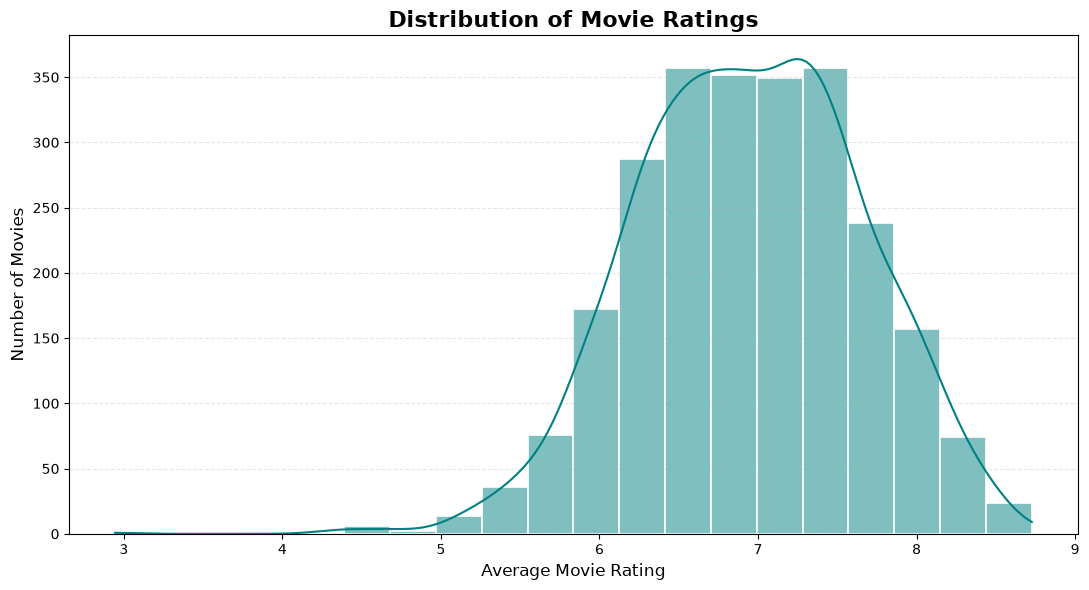

In [16]:
# Select movies with at least one vote
rating_data = movies[movies["vote_count"] > 0]

# Create an improved histogram
plt.figure(figsize=(11, 6))

sns.histplot(
    data=rating_data,
    x="vote_average",
    bins=20,
    kde=True,
    color="teal",
    edgecolor="white",
    linewidth=1.2
)

plt.title("Distribution of Movie Ratings",
          fontsize=16, fontweight="bold")
plt.xlabel("Average Movie Rating", fontsize=12)
plt.ylabel("Number of Movies", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

**Insight:**

The histogram shows the distribution of average ratings across the movies in the dataset. It helps identify the rating ranges where most movies are concentrated. This provides an overview of the general rating patterns and audience responses to the movies.


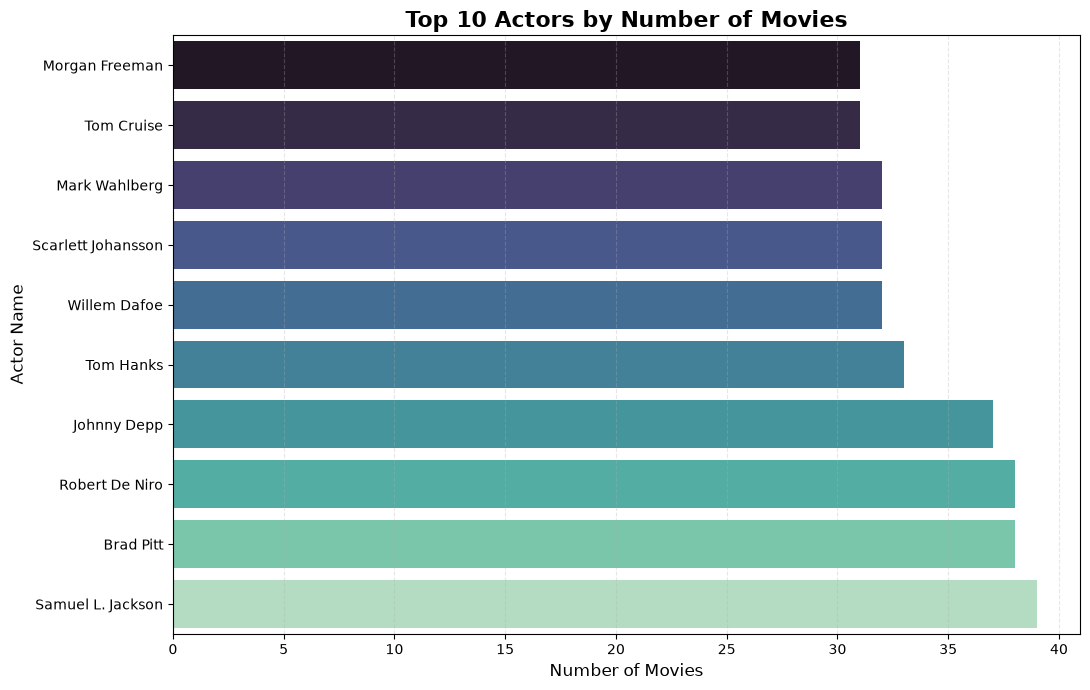

In [17]:
# Count movies for each actor
actor_counts = (
    cast.groupby("actor_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

# Create an improved horizontal bar chart
plt.figure(figsize=(11, 7))

sns.barplot(
    x=actor_counts.values,
    y=actor_counts.index,
    hue=actor_counts.index,
    palette="mako",
    legend=False
)

plt.title("Top 10 Actors by Number of Movies",
          fontsize=16, fontweight="bold")
plt.xlabel("Number of Movies", fontsize=12)
plt.ylabel("Actor Name", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

**Insight:**

The chart highlights the ten actors with the highest number of movie appearances in the dataset. It shows the differences in the number of movie credits among these actors. This analysis helps identify frequently featured actors and understand their representation in the selected movie collection.


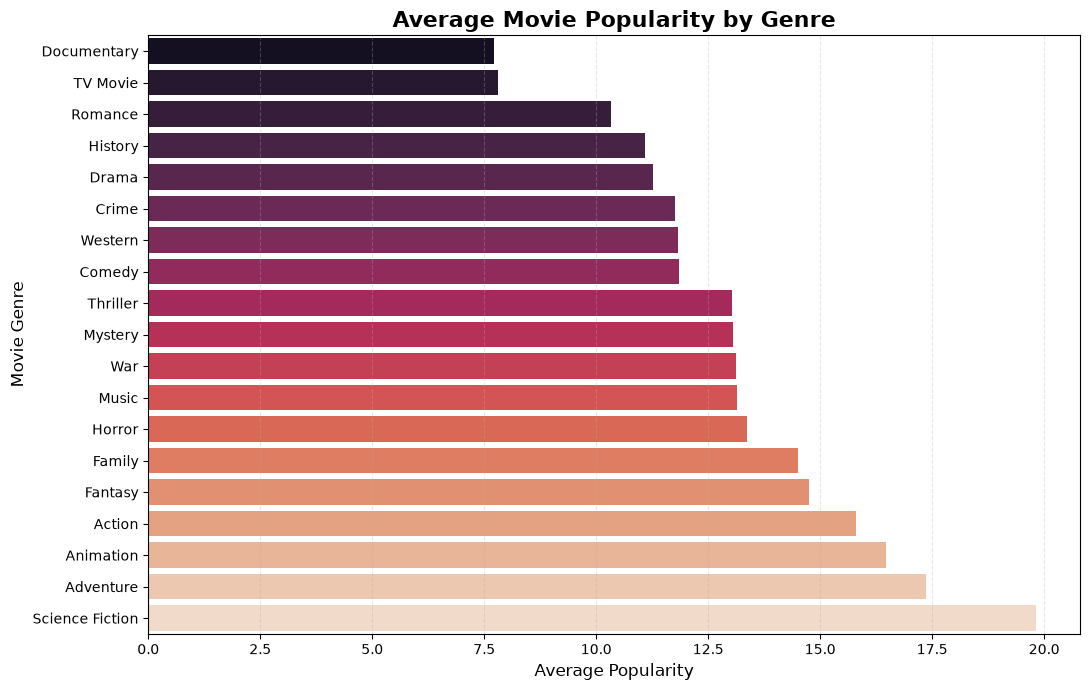

In [18]:
# Combine genre and movie popularity data
genre_popularity = (
    movie_genres
    .merge(genres, on="genre_id")
    .merge(movies[["movie_id", "popularity"]], on="movie_id")
)

# Calculate average popularity by genre
average_popularity = (
    genre_popularity.groupby("genre_name")["popularity"]
    .mean()
    .sort_values(ascending=True)
)

# Create an improved horizontal bar chart
plt.figure(figsize=(11, 7))

sns.barplot(
    x=average_popularity.values,
    y=average_popularity.index,
    hue=average_popularity.index,
    palette="rocket",
    legend=False
)

plt.title("Average Movie Popularity by Genre",
          fontsize=16, fontweight="bold")
plt.xlabel("Average Popularity", fontsize=12)
plt.ylabel("Movie Genre", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

**Insight:**

The chart compares the average popularity scores across different movie genres. It helps identify which genres attract greater audience attention based on the popularity scores. The differences between genres highlight variations in audience interest and engagement.


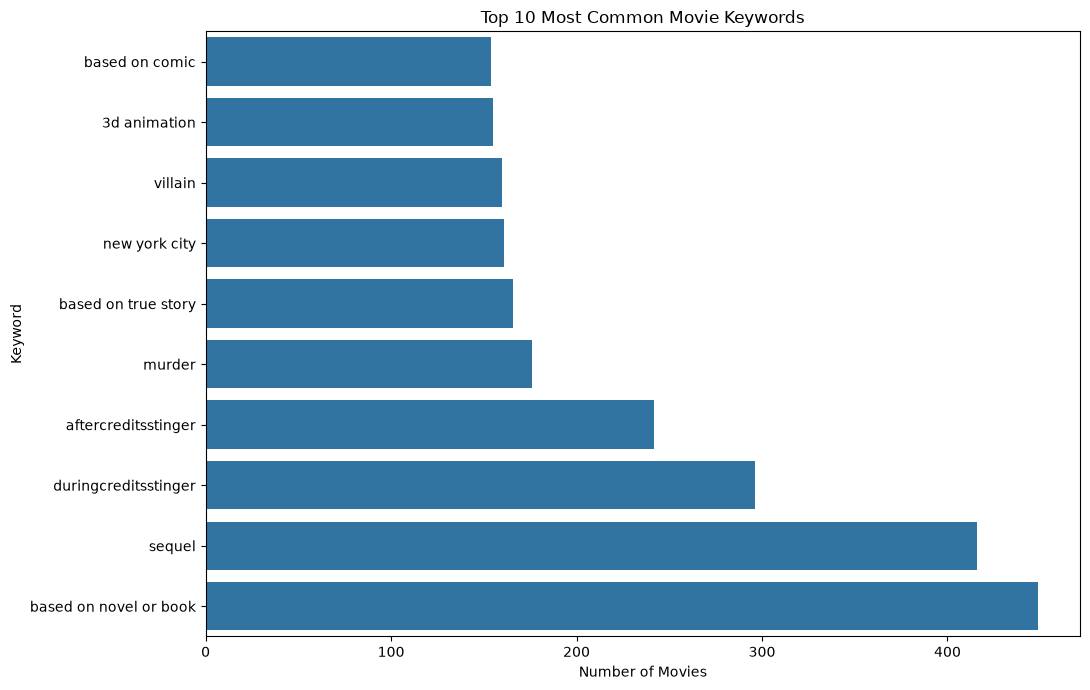

In [10]:
# Count keyword occurrences
top_keywords = (
    movie_keywords.groupby("keyword_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

# Create horizontal bar chart
plt.figure(figsize=(11, 7))

sns.barplot(
    x=top_keywords.values,
    y=top_keywords.index
)

plt.title("Top 10 Most Common Movie Keywords")
plt.xlabel("Number of Movies")
plt.ylabel("Keyword")
plt.tight_layout()
plt.show()

**Insight:**

The chart identifies the ten most frequently occurring keywords associated with movies in the dataset. These keywords reveal common themes and subjects represented across the selected movies. This analysis helps understand the recurring content patterns within the movie collection.


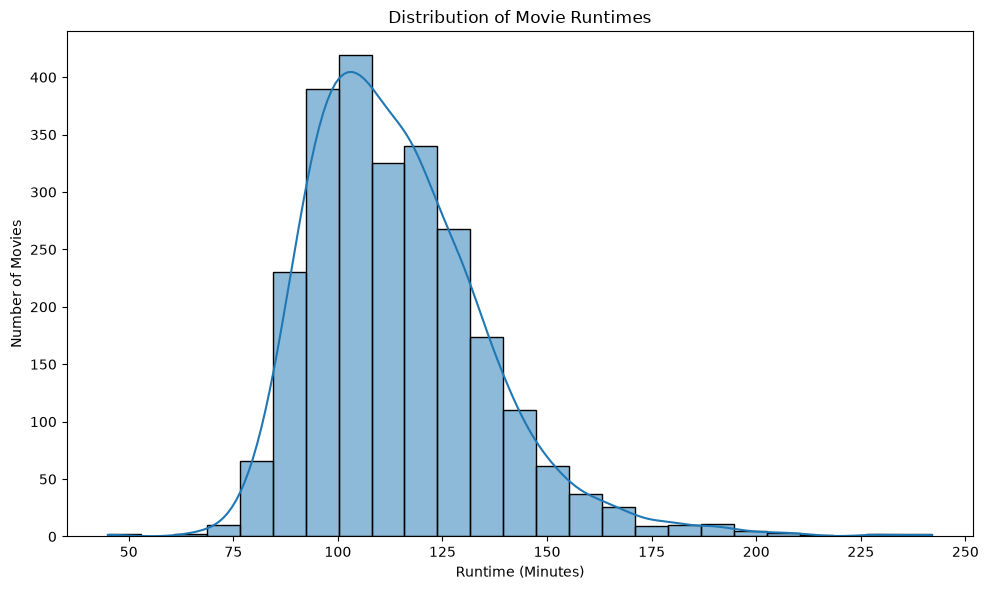

In [11]:
# Select movies with valid runtime
runtime_data = movies[movies["runtime"] > 0]

# Create histogram
plt.figure(figsize=(10, 6))

sns.histplot(
    data=runtime_data,
    x="runtime",
    bins=25,
    kde=True
)

plt.title("Distribution of Movie Runtimes")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

**Insight:**

The histogram illustrates the distribution of movie runtimes in minutes. It helps identify the duration range in which most movies are concentrated. The chart also highlights variations in movie lengths, providing an overview of typical runtime patterns in the dataset.


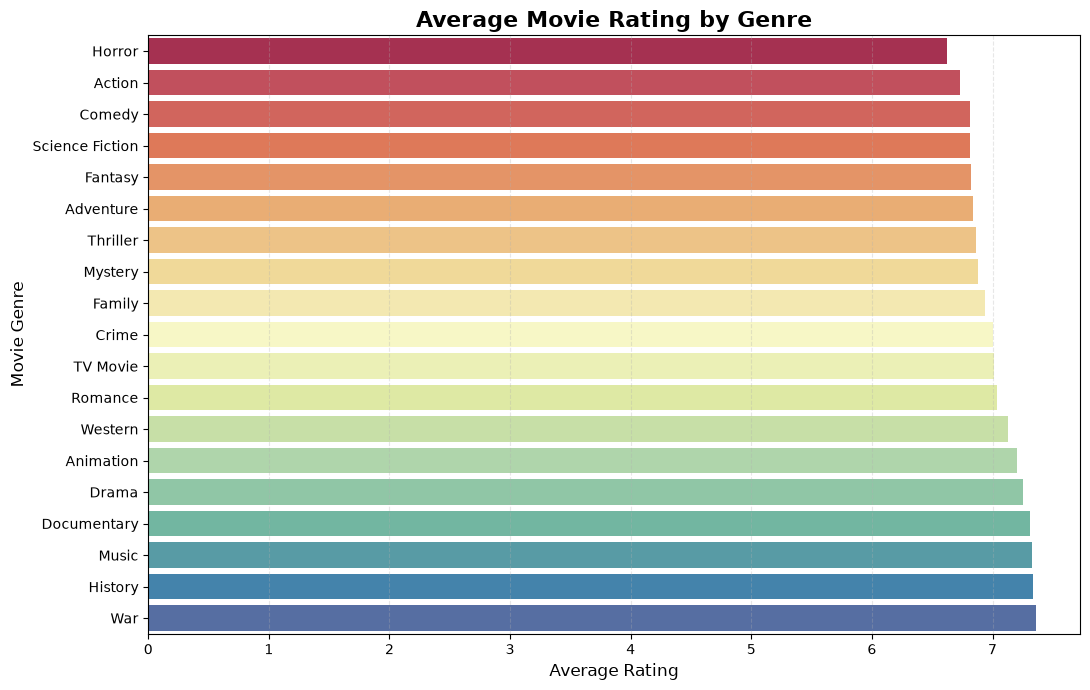

In [19]:
# Combine movie, genre mapping and genre details
genre_ratings = (
    movie_genres
    .merge(genres, on="genre_id")
    .merge(
        movies[["movie_id", "vote_average", "vote_count"]],
        on="movie_id"
    )
)

# Consider movies with at least one vote
genre_ratings = genre_ratings[
    genre_ratings["vote_count"] > 0
]

# Calculate average rating for each genre
average_ratings = (
    genre_ratings.groupby("genre_name")["vote_average"]
    .mean()
    .sort_values(ascending=True)
)

# Create an improved horizontal bar chart
plt.figure(figsize=(11, 7))

sns.barplot(
    x=average_ratings.values,
    y=average_ratings.index,
    hue=average_ratings.index,
    palette="Spectral",
    legend=False
)

plt.title("Average Movie Rating by Genre",
          fontsize=16, fontweight="bold")
plt.xlabel("Average Rating", fontsize=12)
plt.ylabel("Movie Genre", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

**Insight:**

The chart compares the average audience ratings across different movie genres. It helps identify genres that receive higher average ratings and those with comparatively lower ratings. This analysis provides insight into audience appreciation across different types of movies.
